In [12]:
import pandas as pd 

In [13]:
df = pd.read_csv("mushroom.csv")
df.head()

,cap-diameter,cap-shape,gill-attachment,gill-color,stem-height,stem-width,stem-color,season,class
0,1372,2,2,10,3.807467,1545,11,1.804273,1
1,1461,2,2,10,3.807467,1557,11,1.804273,1
2,1371,2,2,10,3.612496,1566,11,1.804273,1
3,1261,6,2,10,3.787572,1566,11,1.804273,1
4,1305,6,2,10,3.711971,1464,11,0.943195,1


In [14]:
df.isna().sum()

cap-diameter       0
cap-shape          0
gill-attachment    0
gill-color         0
stem-height        0
stem-width         0
stem-color         0
season             0
class              0
dtype: int64

In [15]:
df.duplicated().sum()

303

In [16]:
df.drop_duplicates(inplace=True)

In [17]:
df.rename(columns={"class":"target"} , inplace=True)

In [19]:
x = df.drop("target",axis=1)
y = df['target']

In [20]:
from sklearn.model_selection import train_test_split

In [21]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=20)

In [26]:
from sklearn.preprocessing import StandardScaler

In [27]:
scaler = StandardScaler()

In [28]:
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [29]:
from sklearn.linear_model import LogisticRegression

In [30]:
model = LogisticRegression()

In [31]:
model.fit(x_train_scaled,y_train)

LogisticRegression()

In [32]:
y_pred = model.predict(x_test_scaled)

In [41]:
from sklearn.metrics import confusion_matrix,classification_report,accuracy_score,ConfusionMatrixDisplay

In [34]:
accuracy_score(y_pred,y_test)

0.6361775379175584

In [35]:
print(classification_report(y_pred,y_test))

              precision    recall  f1-score   support

           0       0.54      0.61      0.58      4346
           1       0.71      0.65      0.68      6401

    accuracy                           0.64     10747
   macro avg       0.63      0.63      0.63     10747
weighted avg       0.64      0.64      0.64     10747



In [37]:
cm = confusion_matrix(y_test,y_pred)

In [38]:
import seaborn as sns 

<Axes: >

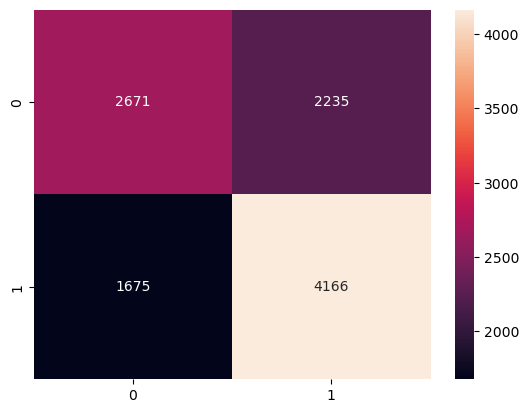

In [39]:
sns.heatmap(cm,annot=True,fmt='d')

In [44]:
import matplotlib.pyplot as plt

In [43]:
cm_plot = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Positive","Negative"])

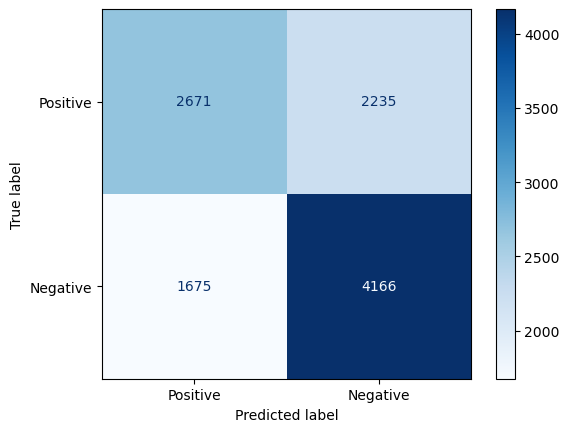

In [46]:
cm_plot.plot(cmap='Blues')
plt.show()